### Aula 1 - Modelo Palete Caixa

In [1]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

#### Dados de entrada e nomenclaturas/simbologias utilizadas 

In [2]:
comprimentos_palete = [8,50,50]
larguras_palete = [6,50,40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [3]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões do caixa: {caixa_comprimento}x{caixa_largura}")



Dimensões do palete: 8x6
Dimensões do caixa: 3x2


---
#### Pela notação do Prof, 
#### A largura do palete sempre deve ser maior comprimento: L>W
#### A largura da caixa sempre deve ser maior comprimento: l>w
#### _um = caixa deitada, _dois = caixa em pé
---

In [4]:
dimensoes_palete = [palete_comprimento, palete_largura]
L,W = sorted(dimensoes_palete, reverse=True)

print(f"Dimensões classificadas do palete: {L}x{W}")

Dimensões classificadas do palete: 8x6


In [5]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse=True) # Caixa _um = Horientação da caixa é deitada

print(f"Dimensões classificadas da caixa deitada (_um): {l_um}x{w_um}")

Dimensões classificadas da caixa deitada (_um): 3x2


In [6]:
l_dois, w_dois = sorted(dimensoes_caixa, reverse=False) # Caixa _dois = Horientação da caixa é em pé 
# l_dois, w_dois = dimensoes_caixa[::-1] # Caixa _dois = Horientação da caixa é em pé 
print(f"Dimensões classificadas da caixa em pé (_dois): {l_dois}x{w_dois}")


Dimensões classificadas da caixa em pé (_dois): 2x3


---
##### Criando uma função para plotar as caixas e o palete
---

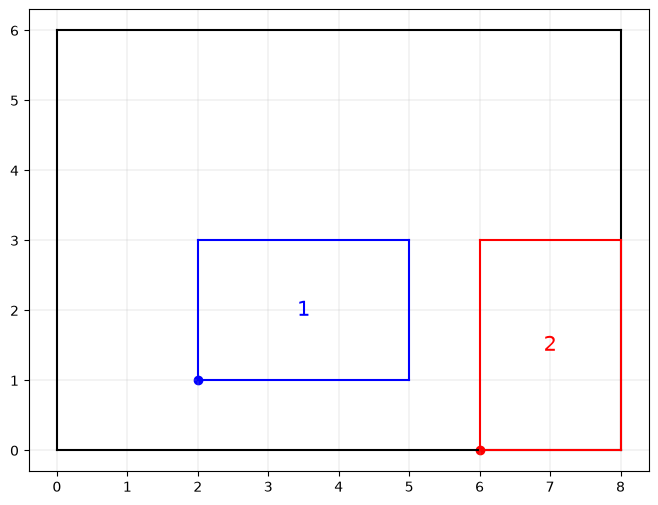

In [7]:
def plotar_caixa(bottom_left:list, #Coordenada da caixa baixo, esquerda
                 l: int, 
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0,x0+l], [y0, y0], color=color)
    plt.plot([x0,x0+l], [y0+w, y0+w], color=color)
    plt.plot([x0,x0], [y0, y0+w], color=color)
    plt.plot([x0+l,x0+l], [y0, y0+w], color=color)
    plt.text(x=x0+l/2, y=y0+w/2, s=label, color=color,
             fontsize = 15, ha="center", va="center")

def plotar_palete(L:int, W:int):
    plt.figure(figsize=(8,6))
    plt.plot([0, L], [0,0], "k-")
    plt.plot([0, 0], [0,W], "k-")
    plt.plot([0, L], [W,W], "k-")
    plt.plot([L, L], [0,W], "k-")
    plt.grid(True, linewidth=0.2)

plotar_palete(L, W)
plotar_caixa(bottom_left=[2,1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6,0], l=2, w=3, color="red", label="2")


---
#### Funções para verificar quantas caixas cabem na horizontal [f_um] (varrendo as combinações das caixas deitadas e em pé) -> soma resulta em p

#### Funções para verificar quantas caixas cabem na vertical [f_dois] (varrendo as combinações das caixas deitadas e em pé) -> soma resulta em q
---

In [ ]:
f_um = lambda n_um, l_um, n_dois, l_dois: n_um*l_um + n_dois*l_dois #p <= L - w_um

f_dois = lambda n_um, w_um, n_dois, w_dois: n_um*w_um + n_dois*w_dois #q <= L - w_um

In [26]:
print(f_um(n_um=2,l_um=3, n_dois=1, l_dois=2))
print(f_dois(n_um=2,w_um=2, n_dois=1, w_dois=3))


8
7


---
#### Varrendo todas as possibilidades para posicionar as caixas na horizontal
---

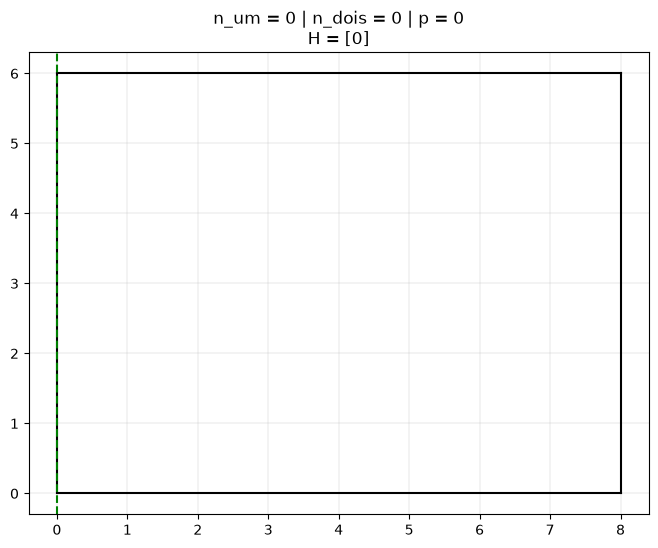

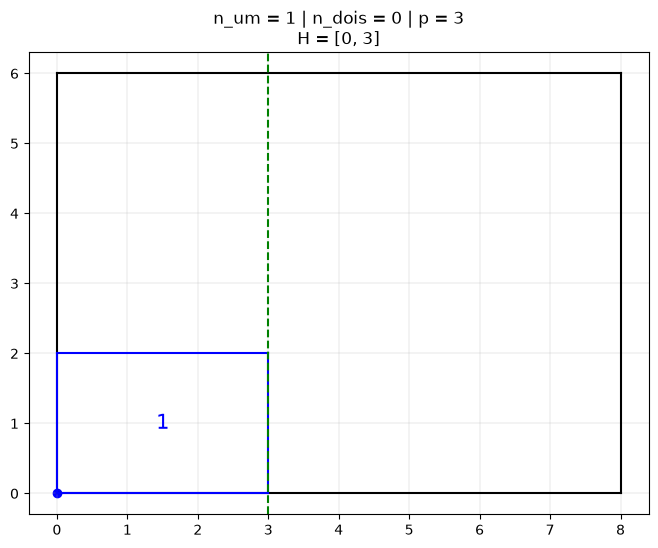

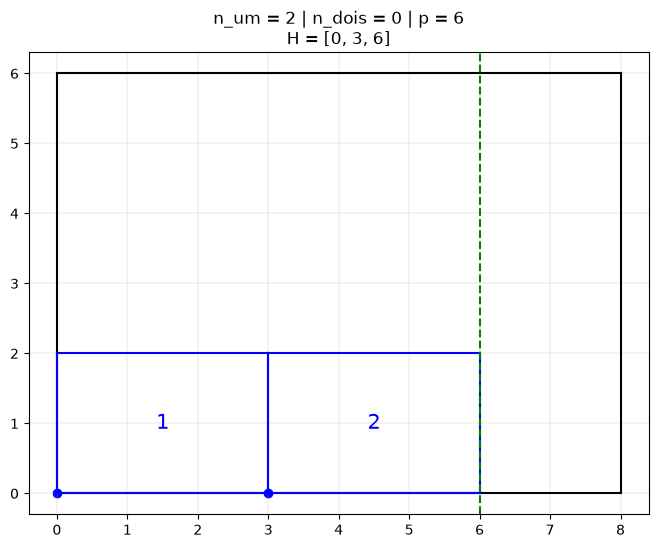

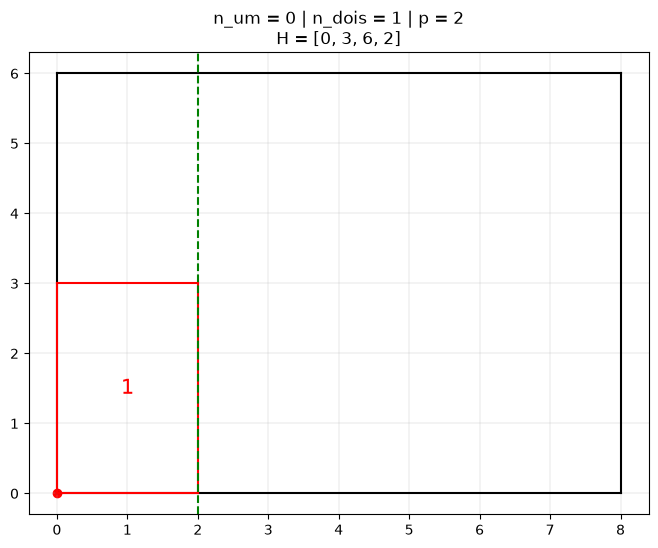

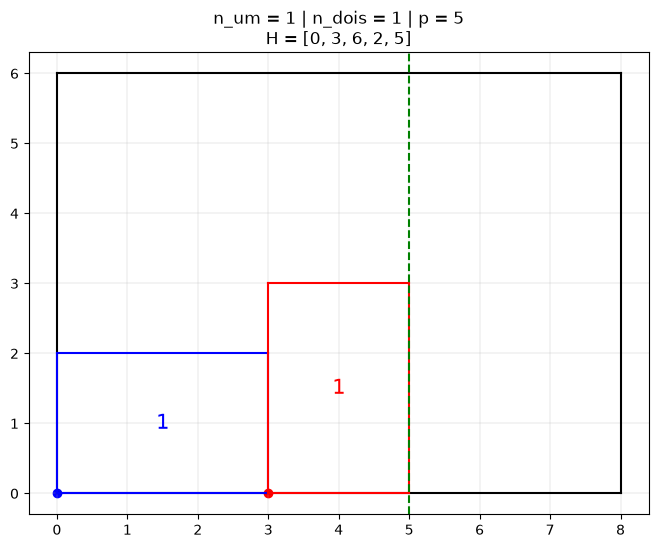

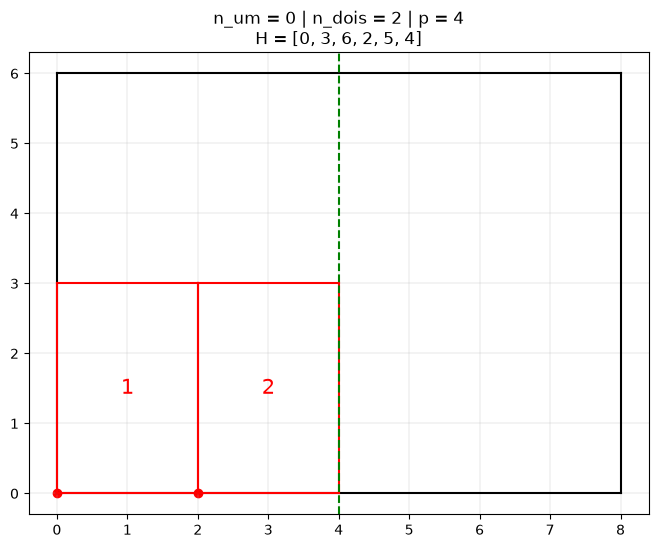

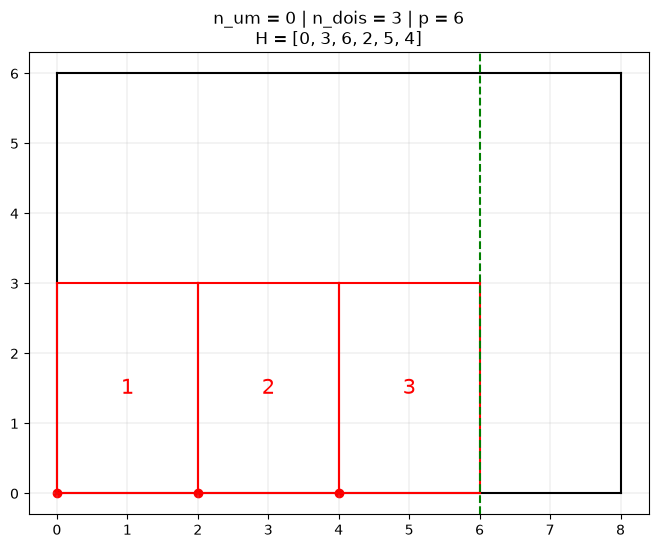

In [39]:
# Lista do H
H = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    # print(n_um, n_dois, p)
    if p<= L-w_um:
        if p not in H:
            H.append(p)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[n*l_um,0], l=l_um, w=w_um, color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um*l_um + n*l_dois,0], l=l_dois, w=w_dois, color="red", label=n+1)
            
        plt.axvline(x=p, color="green", linestyle="--")
        plt.title(f"{n_um = } | {n_dois = } | {p = }\n{H = }")


In [36]:
H

[0, 3, 6, 2, 5, 4]

---
#### Varrendo todas as possibilidades para posicionar as caixas na Vertical
---

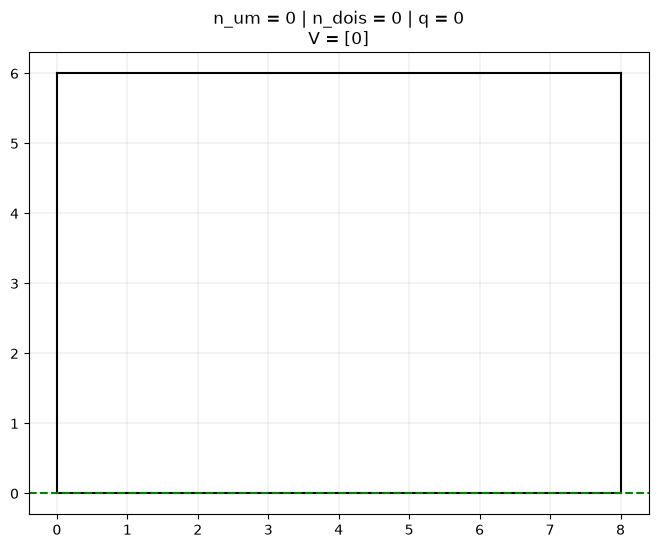

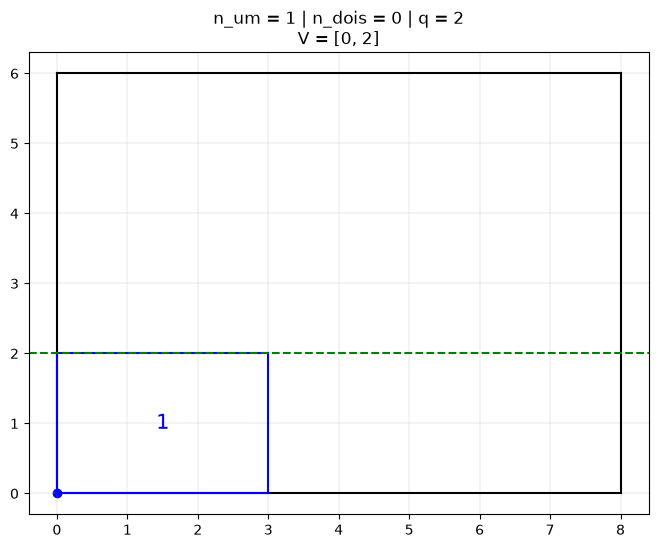

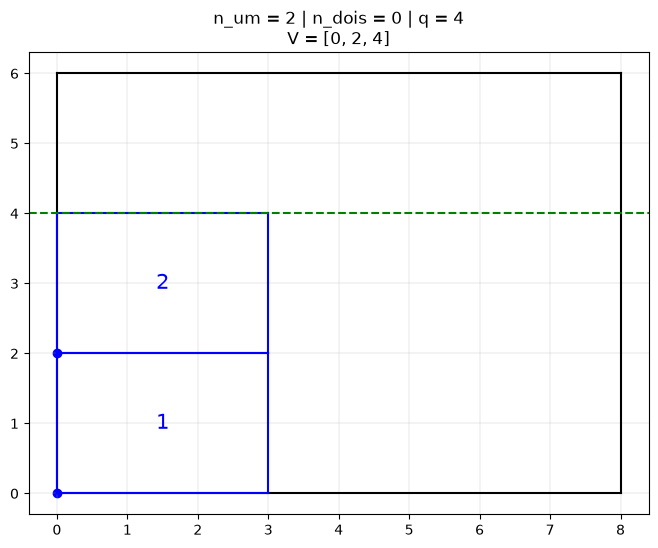

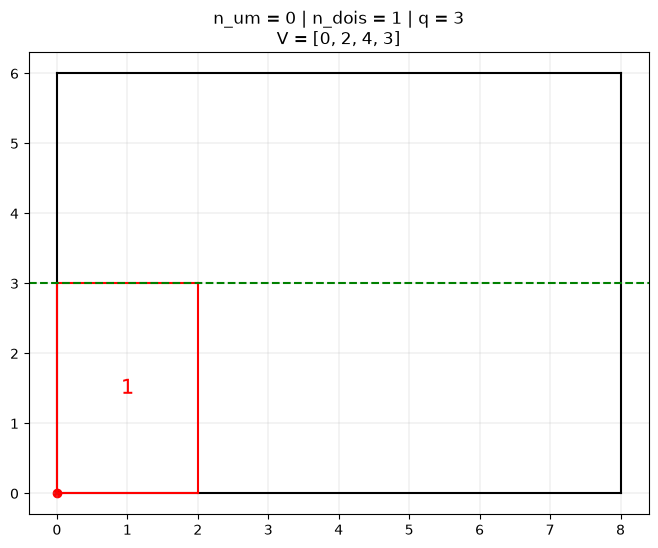

In [ ]:
# Lista do H
V = []
for n_dois, n_um in product(range(L), range(L)):
    # print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    # print(n_um, n_dois, q)
    if q <= W-w_um:
        if q not in V:
            V.append(q)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n*w_um], l=l_um, w=w_um, color="blue", label=n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0,n_um*w_um + n*w_dois], l=l_dois, w=w_dois, color="red", label=n+1)
            
        plt.axhline(y=q, color="green", linestyle="--")
        plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }")


---

In [49]:
# Organizando 

H = sorted(H)
V = sorted(V)

print(H)
print(V)

[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]


In [50]:
lista_rs = list(product(H,V))
display(lista_rs)

[(0, 0),
 (0, 2),
 (0, 3),
 (0, 4),
 (2, 0),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 0),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 0),
 (4, 2),
 (4, 3),
 (4, 4),
 (5, 0),
 (5, 2),
 (5, 3),
 (5, 4),
 (6, 0),
 (6, 2),
 (6, 3),
 (6, 4)]

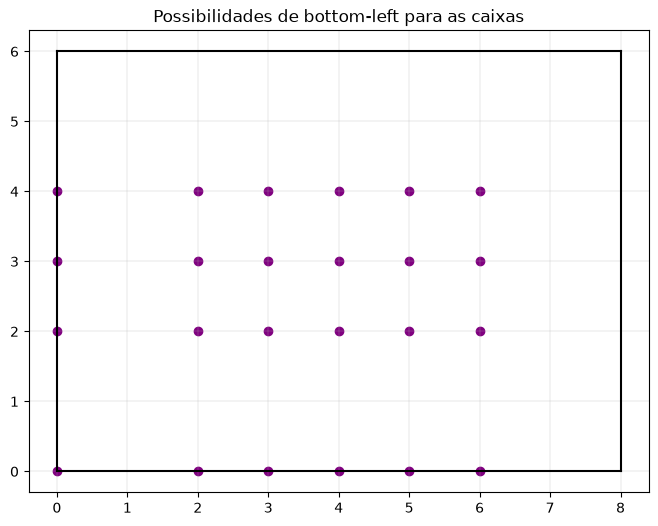

In [53]:
if indice == 0:
    plotar_palete(L, W)
    for r, s in lista_rs:
        plt.scatter(x=r, y=s, color="purple")

    plt.title("Possibilidades de bottom-left para as caixas")
    plt.show()

---
#### Filtrando os pontos 

In [54]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [58]:
# Caixa deitada e caixa em Pé
i = 1
print(ls[i-1], ws[i-1])

3 2


---
#### Lista de tuplas

#### i, p, q :
####  i = 1 ou 2 = deitada ou em pé
####  p, q = par ordenado das possibilidade do bottom left

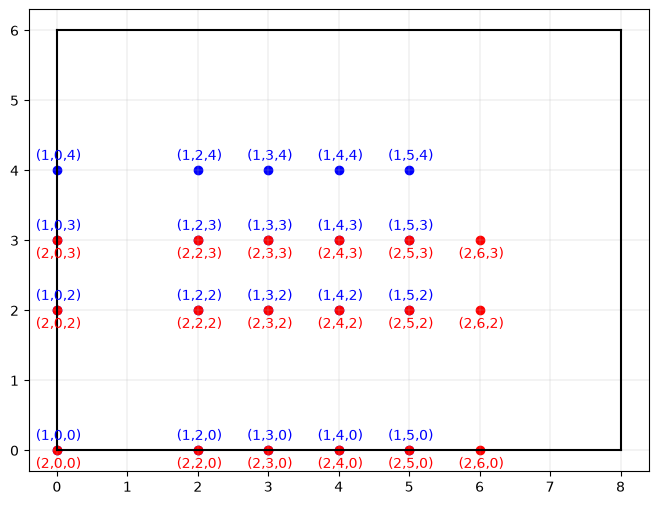

In [69]:
lista_variaveis = []

plotar_palete(L,W)

for (p, q), i in product(lista_rs, [1,2]):
    # print(i,p,q)
    if p+ls[i-1] <= L and q+ws[i-1] <= W: # Checa se cabe ou não no palete
        lista_variaveis.append((i,p,q))

        if indice == 0:
            cor = "blue" if i ==1 else "red"
            plt.scatter(x=p, y=q, color = cor) # plot a bottom-left

            if i==1:
                plt.text(x=p-0.3, y=q+0.15, s=f"({i},{p},{q})", color=cor, fontsize=10)
            else:
                plt.text(x=p-0.3, y=q-0.25, s=f"({i},{p},{q})", color=cor, fontsize=10)


# lista_variaveis

In [70]:
len(lista_variaveis)

38

---
#### Criando a Função Objetivo para ser maximização

In [74]:
prob = plp.LpProblem(name="Palete-Caixa",
                     sense=plp.LpMaximize) #Maximização

display(prob)

Palete-Caixa:
MAXIMIZE
None
VARIABLES

In [76]:
dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis,
                                      lowBound=0, upBound=1,
                                      cat=plp.LpBinary)

display(dict_variaveis)

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 2): C_(1,_0,_2),
 (2, 0, 2): C_(2,_0,_2),
 (1, 0, 3): C_(1,_0,_3),
 (2, 0, 3): C_(2,_0,_3),
 (1, 0, 4): C_(1,_0,_4),
 (1, 2, 0): C_(1,_2,_0),
 (2, 2, 0): C_(2,_2,_0),
 (1, 2, 2): C_(1,_2,_2),
 (2, 2, 2): C_(2,_2,_2),
 (1, 2, 3): C_(1,_2,_3),
 (2, 2, 3): C_(2,_2,_3),
 (1, 2, 4): C_(1,_2,_4),
 (1, 3, 0): C_(1,_3,_0),
 (2, 3, 0): C_(2,_3,_0),
 (1, 3, 2): C_(1,_3,_2),
 (2, 3, 2): C_(2,_3,_2),
 (1, 3, 3): C_(1,_3,_3),
 (2, 3, 3): C_(2,_3,_3),
 (1, 3, 4): C_(1,_3,_4),
 (1, 4, 0): C_(1,_4,_0),
 (2, 4, 0): C_(2,_4,_0),
 (1, 4, 2): C_(1,_4,_2),
 (2, 4, 2): C_(2,_4,_2),
 (1, 4, 3): C_(1,_4,_3),
 (2, 4, 3): C_(2,_4,_3),
 (1, 4, 4): C_(1,_4,_4),
 (1, 5, 0): C_(1,_5,_0),
 (2, 5, 0): C_(2,_5,_0),
 (1, 5, 2): C_(1,_5,_2),
 (2, 5, 2): C_(2,_5,_2),
 (1, 5, 3): C_(1,_5,_3),
 (2, 5, 3): C_(2,_5,_3),
 (1, 5, 4): C_(1,_5,_4),
 (2, 6, 0): C_(2,_6,_0),
 (2, 6, 2): C_(2,_6,_2),
 (2, 6, 3): C_(2,_6,_3)}

In [79]:
dict_variaveis.values()


dict_values([C_(1,_0,_0), C_(2,_0,_0), C_(1,_0,_2), C_(2,_0,_2), C_(1,_0,_3), C_(2,_0,_3), C_(1,_0,_4), C_(1,_2,_0), C_(2,_2,_0), C_(1,_2,_2), C_(2,_2,_2), C_(1,_2,_3), C_(2,_2,_3), C_(1,_2,_4), C_(1,_3,_0), C_(2,_3,_0), C_(1,_3,_2), C_(2,_3,_2), C_(1,_3,_3), C_(2,_3,_3), C_(1,_3,_4), C_(1,_4,_0), C_(2,_4,_0), C_(1,_4,_2), C_(2,_4,_2), C_(1,_4,_3), C_(2,_4,_3), C_(1,_4,_4), C_(1,_5,_0), C_(2,_5,_0), C_(1,_5,_2), C_(2,_5,_2), C_(1,_5,_3), C_(2,_5,_3), C_(1,_5,_4), C_(2,_6,_0), C_(2,_6,_2), C_(2,_6,_3)])

In [80]:
sum(dict_variaveis.values())


1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0

In [81]:
# Adicionando no Prob

prob += sum(dict_variaveis.values())
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
VARIABLES
0 <= C_(1,_0,_0) <= 1 Integer
0 <= C_(1,_0,_2) <= 1 Integer
0 <= C_(1,_0,_3) <= 1 Integer
0 <= C_(1,_0,_4) <= 1 Integer
0 <= C_(1,_2,_0) <= 1 Integer
0 <= C_(1,_2,_2) <= 1 Integer
0 <= C_(1,_2,_3) <= 1 Integer
0 <= C_(1,_2,_4) <= 1 Integer
0 <= C_(1,_3,_0) <= 1 Integer
0 <= C_(1,_3,_2) <= 1 Integer
0 <= C_(1,_3,_3) <= 1 Integer
0 <= C_(1,_3,_4) <= 1 Integ